<a href="https://colab.research.google.com/github/nishithy13/DS2002-Midterm/blob/main/DS2002-Midterm%20/notebooks/walmart_hurricane_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics

**DS2002 Midterm Project**

This notebook cleans the supplied September 2024 transaction and reference data, compares the seven days before the selected event date with the preceding seven-day baseline, and examines weather, store regions, Pop-Tarts, and board-game inventory.

**Analysis choices and limits**
- Event date: September 26, 2024. The supplied files do not include a predicted storm track, so Question 4 compares the store regions in `store_locations.csv` as a geographic proxy.
- Sales timestamps have no timezone offset. They are treated as local Florida time; daily Open-Meteo data is requested in `America/New_York`.
- Empty transaction timestamps are kept out of date-based analyses rather than imputed.
- The board-game question uses the SQLite database because it is an explicitly supplied project file. The database's `daily_sales_summary` is category-level, so it cannot prove board-game-only demand.
- Reflections are omitted as requested.


## 1. Load and inspect the supplied data

All local inputs come from the supplied files in the Downloads folder. The only external data source is the required historical weather API, called in Question 3.

In [ ]:
from pathlib import Path
import re
import sqlite3
from datetime import timedelta
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display, Markdown

DATA_DIR = Path.home() / "Downloads"
FILES = {
    "transactions": DATA_DIR / "walmart_transactions (1).csv",
    "stores": DATA_DIR / "store_locations.csv",
    "products": DATA_DIR / "product_catalog.csv",
    "distribution_centers": DATA_DIR / "distribution_centers.csv",
    "database": DATA_DIR / "inventory_and_sales.db",
}
missing_files = [str(path) for path in FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing supplied input file(s): " + ", ".join(missing_files))

transactions_raw = pd.read_csv(FILES["transactions"], dtype={"store_id": "string", "sku": "string"})
stores_raw = pd.read_csv(FILES["stores"], dtype={"store_id": "string"})
products_raw = pd.read_csv(FILES["products"], dtype={"sku": "string"})
distribution_centers = pd.read_csv(FILES["distribution_centers"])

with sqlite3.connect(FILES["database"]) as connection:
    db_sales_raw = pd.read_sql_query("SELECT * FROM daily_sales_summary", connection)
    inventory_raw = pd.read_sql_query("SELECT * FROM inventory_levels", connection)

for name, frame in {
    "transactions": transactions_raw,
    "stores": stores_raw,
    "products": products_raw,
    "distribution centers": distribution_centers,
    "SQLite daily sales": db_sales_raw,
    "SQLite inventory": inventory_raw,
}.items():
    print(f"{name}: {frame.shape}")
    print(frame.dtypes.to_dict())
    print("missing values:", frame.isna().sum().to_dict())
    print()

display(transactions_raw.head())
display(products_raw.head())


transactions: (25562, 8)
{'transaction_id': dtype('O'), 'store_id': string[python], 'timestamp': dtype('O'), 'sku': string[python], 'product_name': dtype('O'), 'category': dtype('O'), 'quantity': dtype('int64'), 'unit_price': dtype('O')}
missing values: {'transaction_id': 0, 'store_id': 0, 'timestamp': 886, 'sku': 0, 'product_name': 0, 'category': 0, 'quantity': 0, 'unit_price': 0}

stores: (14, 8)
{'store_id': string[python], 'store_name': dtype('O'), 'city': dtype('O'), 'state': dtype('O'), 'zip_code': dtype('int64'), 'latitude': dtype('float64'), 'longitude': dtype('float64'), 'region': dtype('O')}
missing values: {'store_id': 0, 'store_name': 0, 'city': 0, 'state': 0, 'zip_code': 0, 'latitude': 1, 'longitude': 1, 'region': 0}

products: (45, 7)
{'sku': string[python], 'product_name': dtype('O'), 'category': dtype('O'), 'subcategory': dtype('O'), 'unit_cost': dtype('float64'), 'supplier': dtype('O'), 'package_size': dtype('O')}
missing values: {'sku': 0, 'product_name': 0, 'category

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


## 2. Identify and clean data issues

The source files contain repeated transaction IDs, multiple timestamp formats, missing timestamps, negative quantities, price strings with currency symbols, inconsistent store IDs and category labels, and fragmented Pop-Tart SKUs. The next cells report these issues, then apply explicit and reviewable cleaning rules.

In [ ]:
print("Duplicate transaction IDs:", transactions_raw["transaction_id"].duplicated().sum())
print("Missing/placeholder timestamps:", transactions_raw["timestamp"].isna().sum() + transactions_raw["timestamp"].astype("string").str.strip().str.lower().isin(["", "nan", "null", "n/a"]).sum())
print("Negative quantities:", pd.to_numeric(transactions_raw["quantity"], errors="coerce").lt(0).sum())
print("Raw store ID variants:", transactions_raw["store_id"].nunique())
print("Raw category labels:", sorted(transactions_raw["category"].dropna().astype(str).unique()))
print("Raw SKU count:", transactions_raw["sku"].nunique())


Duplicate transaction IDs: 30
Missing/placeholder timestamps: 886
Negative quantities: 130
Raw store ID variants: 60
Raw category labels: ['ALCOHOL', 'Alcohol', 'Alcoholic Beverages', 'BABY', 'BREAKFAST', 'Baby', 'Baby Products', 'Breakfast', 'Breakfast Foods', 'ELECTRONICS', 'EMERGENCY', 'ENTERTAINMENT', 'Electronics', 'Emergency', 'Emergency Supplies', 'Entertainment', 'GROCERY', 'Games & Entertainment', 'Groceries', 'Grocery', 'HEALTH', 'HOUSEHOLD', 'Health', 'Health & Wellness', 'Household', 'Household Essentials', 'SNACKS', 'Snacks', 'baby', 'breakfast', 'electronics', 'emergency', 'entertainment', 'grocery', 'health', 'household', 'snacks']
Raw SKU count: 45


In [ ]:
def clean_store_id(value):
    text = str(value).strip().upper().replace("_", "-")
    match = re.fullmatch(r"FL-?(\d{3})", text)
    return f"FL-{match.group(1)}" if match else text

category_aliases = {
    "grocery": "Grocery", "groceries": "Grocery",
    "breakfast": "Breakfast", "breakfast foods": "Breakfast",
    "emergency": "Emergency", "emergency supplies": "Emergency",
    "electronics": "Electronics",
    "entertainment": "Entertainment", "games & entertainment": "Entertainment",
    "household": "Household", "household essentials": "Household",
    "baby": "Baby", "baby products": "Baby",
    "health": "Health", "health & wellness": "Health",
    "snacks": "Snacks",
    "alcohol": "Alcohol", "alcoholic beverages": "Alcohol",
}

def clean_category(value):
    key = " ".join(str(value).strip().lower().split())
    return category_aliases.get(key, "Other")

transactions = transactions_raw.drop_duplicates(subset="transaction_id", keep="first").copy()
transactions["store_id"] = transactions["store_id"].map(clean_store_id)
transactions["sku"] = transactions["sku"].astype("string").str.strip().str.upper()
transactions["timestamp_parsed"] = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
transactions["date"] = transactions["timestamp_parsed"].dt.normalize()
transactions["quantity"] = pd.to_numeric(transactions["quantity"], errors="coerce")
transactions["unit_price"] = pd.to_numeric(
    transactions["unit_price"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)
transactions["category"] = transactions["category"].map(clean_category)
transactions = transactions[transactions["quantity"].notna() & transactions["quantity"].gt(0)].copy()

products = products_raw.copy()
products["sku"] = products["sku"].astype("string").str.strip().str.upper()
products["catalog_category"] = products["category"].map(clean_category)
products["product_name_clean"] = products["product_name"].astype("string").str.strip()
product_lookup = products[["sku", "product_name_clean", "catalog_category"]].drop_duplicates("sku")
transactions = transactions.merge(product_lookup, on="sku", how="left", validate="many_to_one")
transactions["category"] = transactions["category"].where(
    transactions["category"].ne("Other"), transactions["catalog_category"]
)
transactions["product_name"] = transactions["product_name"].fillna(transactions["product_name_clean"])

stores = stores_raw.copy()
stores["store_id"] = stores["store_id"].map(clean_store_id)
stores["latitude"] = pd.to_numeric(stores["latitude"], errors="coerce")
stores["longitude"] = pd.to_numeric(stores["longitude"], errors="coerce")
stores["region"] = stores["region"].astype("string").str.strip().str.title()
# Keep one row per normalized store ID; this resolves duplicate location records.
stores = stores.drop_duplicates("store_id", keep="first").copy()

date_transactions = transactions[transactions["date"].notna()].copy()
print("Rows before cleaning:", len(transactions_raw))
print("Rows after exact transaction-ID deduplication and invalid-quantity removal:", len(transactions))
print("Rows with missing/unparseable timestamps (excluded only from date analyses):", transactions["date"].isna().sum())
print("Unmatched transaction SKUs:", transactions["product_name_clean"].isna().sum())
print("Cleaned categories:", sorted(transactions["category"].dropna().unique()))
print("Normalized store IDs:", transactions["store_id"].nunique())
display(transactions[["transaction_id", "store_id", "timestamp", "sku", "category", "quantity", "unit_price"]].head())


Rows before cleaning: 25562
Rows after exact transaction-ID deduplication and invalid-quantity removal: 25402
Rows with missing/unparseable timestamps (excluded only from date analyses): 881
Unmatched transaction SKUs: 0
Cleaned categories: ['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']
Normalized store IDs: 12


,transaction_id,store_id,timestamp,sku,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,Grocery,1,3.15
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Grocery,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Household,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Electronics,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Alcohol,3,18.82


In [ ]:
pop_tart_pattern = r"pop[- ]?tarts?"
pop_tart_catalog = products[products["product_name_clean"].str.contains(pop_tart_pattern, case=False, regex=True, na=False)]
pop_tart_skus = set(pop_tart_catalog["sku"].dropna())
sku_mapping = pop_tart_catalog[["sku", "product_name_clean", "catalog_category"]].rename(
    columns={"product_name_clean": "canonical_product", "catalog_category": "canonical_category"}
)
print("Pop-Tart SKU mapping from the supplied catalog:")
display(sku_mapping)


Pop-Tart SKU mapping from the supplied catalog:


,sku,canonical_product,canonical_category
0,PT-12,pop-tarts strawberry,Breakfast
1,SKU#459812,Strawberry Pop-Tart,Breakfast
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
3,PT_STRAWBERRY,pop-tarts strawberry,Breakfast


## Question 1: Demand surge identification

The surge window is September 19–25, 2024. The equal-length baseline is September 12–18. Quantities are summed by cleaned category and date; the chart shows daily units for the five categories with the largest percentage increase. A zero baseline is reported as undefined rather than an infinite percentage.

,baseline_units,surge_units,baseline_daily_avg,surge_daily_avg,increase_pct
category,,,,,
Breakfast,771,2638,110.1,376.9,242.2
Emergency,2968,7045,424.0,1006.4,137.4
Electronics,549,1231,78.4,175.9,124.2
Entertainment,771,1600,110.1,228.6,107.5
Alcohol,471,972,67.3,138.9,106.4
Health,336,665,48.0,95.0,97.9
Household,689,1234,98.4,176.3,79.1
Grocery,1352,2146,193.1,306.6,58.7
Baby,637,936,91.0,133.7,46.9


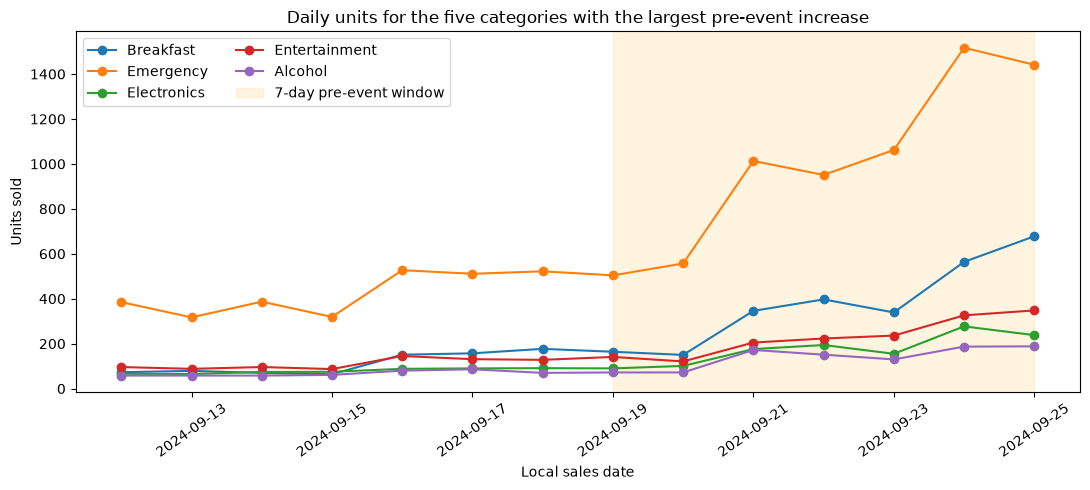

**Finding.** Breakfast had the largest measured increase: 242.2% in average daily units, comparing September 19–25 with September 12–18. This is a descriptive comparison from the supplied synthetic transactions, not a causal estimate.

In [ ]:
from datetime import timedelta

EVENT_DATE = pd.Timestamp("2024-09-26")
SURGE_DATES = pd.date_range(EVENT_DATE - timedelta(days=7), EVENT_DATE - timedelta(days=1), freq="D")
BASELINE_DATES = pd.date_range(EVENT_DATE - timedelta(days=14), EVENT_DATE - timedelta(days=8), freq="D")

daily_category = date_transactions.groupby(["date", "category"], as_index=False)["quantity"].sum()
baseline_category = daily_category[daily_category["date"].isin(BASELINE_DATES)].groupby("category")["quantity"].sum()
surge_category = daily_category[daily_category["date"].isin(SURGE_DATES)].groupby("category")["quantity"].sum()
q1 = pd.concat([baseline_category.rename("baseline_units"), surge_category.rename("surge_units")], axis=1).fillna(0)
q1["baseline_daily_avg"] = q1["baseline_units"] / len(BASELINE_DATES)
q1["surge_daily_avg"] = q1["surge_units"] / len(SURGE_DATES)
q1["increase_pct"] = ((q1["surge_daily_avg"] / q1["baseline_daily_avg"]) - 1) * 100
q1.loc[q1["baseline_daily_avg"].eq(0), "increase_pct"] = float("nan")
q1 = q1.sort_values("increase_pct", ascending=False)
top_categories = q1.dropna(subset=["increase_pct"]).head(5).index.tolist()
display(q1.round(1))

fig, ax = plt.subplots(figsize=(11, 5))
for category in top_categories:
    series = daily_category[(daily_category["category"] == category) & (daily_category["date"].isin(BASELINE_DATES.union(SURGE_DATES)))]
    ax.plot(series["date"], series["quantity"], marker="o", label=category)
ax.axvspan(SURGE_DATES.min(), SURGE_DATES.max(), color="orange", alpha=0.12, label="7-day pre-event window")
ax.set(title="Daily units for the five categories with the largest pre-event increase", xlabel="Local sales date", ylabel="Units sold")
ax.legend(ncol=2)
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

if len(q1.dropna(subset=["increase_pct"])):
    winner = q1.dropna(subset=["increase_pct"]).iloc[0]
    display(Markdown(
        f"**Finding.** {q1.dropna(subset=['increase_pct']).index[0]} had the largest measured increase: "
        f"{winner['increase_pct']:.1f}% in average daily units, comparing September 19–25 with September 12–18. "
        "This is a descriptive comparison from the supplied synthetic transactions, not a causal estimate."
    ))


## Question 2: The Pop-Tarts effect

The fragmented view retains a separate daily line for each catalog SKU and uses the uncleaned transaction rows, so duplicate rows remain visible. The consolidated view uses deduplicated, validated transactions and combines every catalog-matched Strawberry Pop-Tart SKU into one daily total. The comparison reports daily volume and shows how SKU fragmentation can understate demand when a decision maker looks at only one variant.

Catalog-mapped Pop-Tart SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
Total Pop-Tart units, fragmented raw rows: 5006
Total Pop-Tart units, deduplicated and consolidated: 5005
Peak daily units, raw rows: 678
Peak daily units, cleaned family total: 678


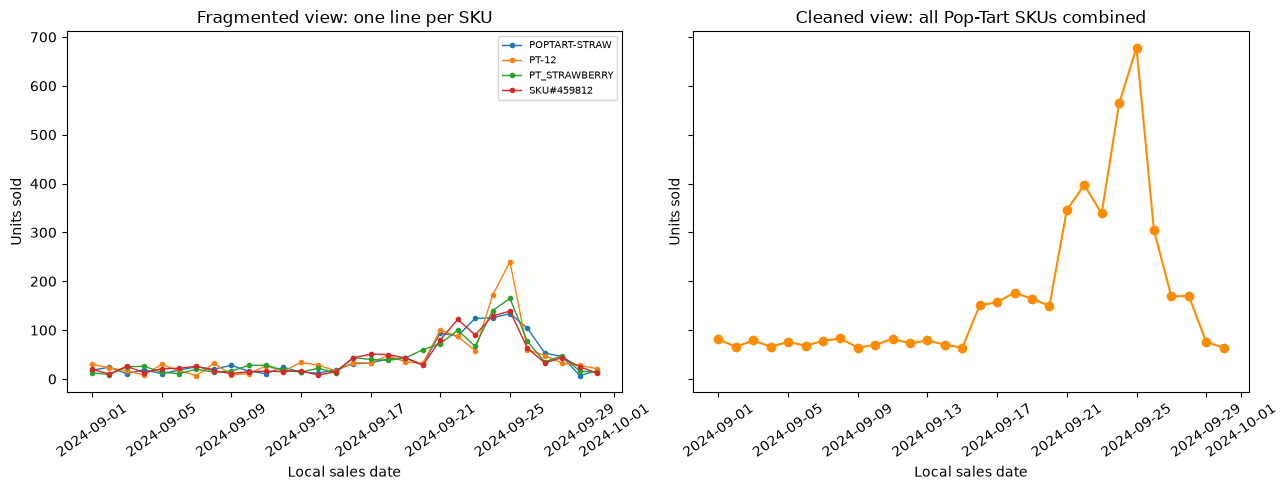

**Business implication.** A SKU-by-SKU replenishment review can miss total demand spread across variants and allocate too little stock to the product family. The consolidated series is the family-level signal; individual SKU/package decisions still require SKU-level inventory and package-size checks.

In [ ]:
raw_pop = transactions_raw.copy()
raw_pop["sku"] = raw_pop["sku"].astype("string").str.strip().str.upper()
raw_pop["raw_timestamp"] = pd.to_datetime(raw_pop["timestamp"], format="mixed", errors="coerce")
raw_pop["date"] = raw_pop["raw_timestamp"].dt.normalize()
raw_pop["quantity"] = pd.to_numeric(raw_pop["quantity"], errors="coerce")
raw_pop["product_match"] = raw_pop["product_name"].astype("string").str.contains(pop_tart_pattern, case=False, regex=True, na=False)
raw_pop = raw_pop[(raw_pop["sku"].isin(pop_tart_skus) | raw_pop["product_match"]) & raw_pop["date"].notna() & raw_pop["quantity"].gt(0)]
raw_pop_sku_daily = raw_pop.groupby(["date", "sku"], as_index=False)["quantity"].sum()

clean_pop = date_transactions[date_transactions["sku"].isin(pop_tart_skus)].copy()
clean_pop_daily = clean_pop.groupby("date", as_index=False)["quantity"].sum()
clean_pop_daily = clean_pop_daily.rename(columns={"quantity": "consolidated_units"})
raw_pop_daily = raw_pop.groupby("date", as_index=False)["quantity"].sum()
print("Catalog-mapped Pop-Tart SKUs:", sorted(pop_tart_skus))
print("Total Pop-Tart units, fragmented raw rows:", int(raw_pop["quantity"].sum()))
print("Total Pop-Tart units, deduplicated and consolidated:", int(clean_pop["quantity"].sum()))
print("Peak daily units, raw rows:", int(raw_pop_daily["quantity"].max()))
print("Peak daily units, cleaned family total:", int(clean_pop_daily["consolidated_units"].max()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for sku, part in raw_pop_sku_daily.groupby("sku"):
    axes[0].plot(part["date"], part["quantity"], marker=".", linewidth=1, label=sku)
axes[0].set_title("Fragmented view: one line per SKU")
axes[0].legend(fontsize=7)
axes[1].plot(clean_pop_daily["date"], clean_pop_daily["consolidated_units"], color="darkorange", marker="o")
axes[1].set_title("Cleaned view: all Pop-Tart SKUs combined")
for ax in axes:
    ax.set_xlabel("Local sales date")
    ax.set_ylabel("Units sold")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

display(Markdown(
    "**Business implication.** A SKU-by-SKU replenishment review can miss total demand spread across variants and allocate too little stock to the product family. "
    "The consolidated series is the family-level signal; individual SKU/package decisions still require SKU-level inventory and package-size checks."
))


## Question 3: Weather correlation and lag

The notebook calls the Open-Meteo Historical Weather API for each unique supplied store location with coordinates. Hourly precipitation, wind speed, and surface pressure are aggregated to store-local calendar days, then joined to cleaned daily store sales. Correlations describe association only. The lag check tests whether weather severity on a date aligns more strongly with sales one or two days later; the short synthetic period limits interpretation.

Weather API: https://archive-api.open-meteo.com/v1/archive
Stores with coordinates queried: 11
Stores with successful weather data: 11
Stores without supplied coordinates: ['FL-619']
Store-day weather/sales correlations:


,correlation
precipitation_mm,-0.215
wind_speed_kmh_max,0.218
surface_pressure_hpa_mean,-0.208


,weather_leads_sales_by_days,correlation
0,0,0.083
1,1,-0.163
2,2,-0.242


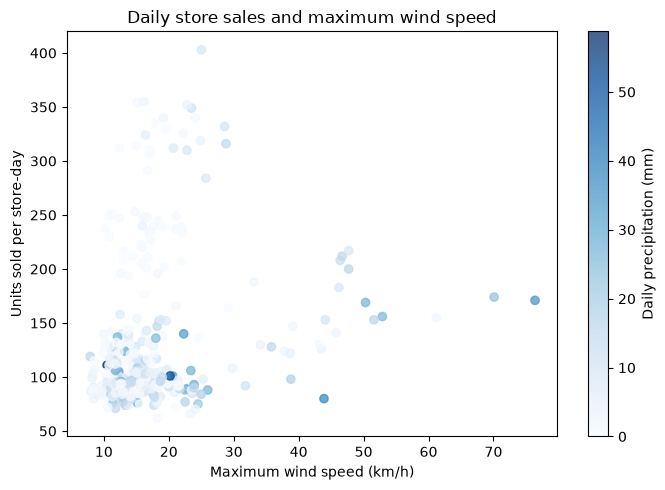

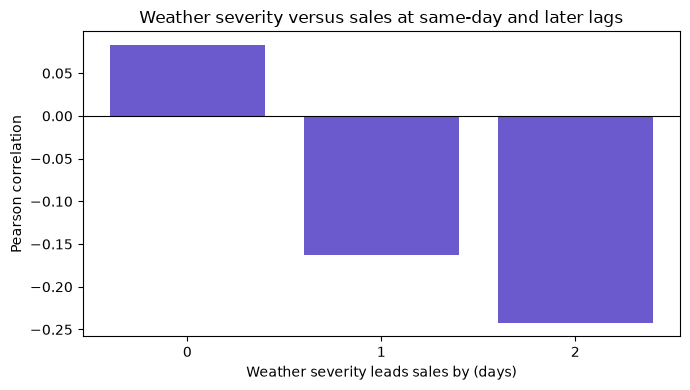

**Finding.** Same-day, one-day, and two-day weather alignments were tested. No clear positive purchasing lag appears in these data; the strongest positive correlation was 0.08 at a 0-day lead. The largest absolute correlation was at a 2-day lead (r=-0.24). These exploratory correlations do not establish that weather caused the sales change.

In [ ]:
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
weather_parts = []
weather_errors = []
weather_locations = stores.dropna(subset=["latitude", "longitude"]).drop_duplicates("store_id")

for _, store in weather_locations.iterrows():
    params = {
        "latitude": store["latitude"],
        "longitude": store["longitude"],
        "start_date": "2024-09-01",
        "end_date": "2024-09-30",
        "hourly": "precipitation,wind_speed_10m,surface_pressure",
        "timezone": "America/New_York",
    }
    try:
        response = requests.get(OPEN_METEO_URL, params=params, timeout=30)
        response.raise_for_status()
        payload = response.json()
        hourly = payload.get("hourly", {})
        part = pd.DataFrame({
            "time": hourly.get("time", []),
            "precipitation_mm": hourly.get("precipitation", []),
            "wind_speed_kmh": hourly.get("wind_speed_10m", []),
            "surface_pressure_hpa": hourly.get("surface_pressure", []),
        })
        if not part.empty:
            part["store_id"] = store["store_id"]
            part["date"] = pd.to_datetime(part["time"], errors="coerce").dt.normalize()
            for column in ["precipitation_mm", "wind_speed_kmh", "surface_pressure_hpa"]:
                part[column] = pd.to_numeric(part[column], errors="coerce")
            weather_parts.append(part)
    except (requests.RequestException, ValueError, KeyError) as error:
        weather_errors.append(f"{store['store_id']}: {error}")

if weather_parts:
    weather_hourly = pd.concat(weather_parts, ignore_index=True)
    weather_daily = weather_hourly.groupby(["store_id", "date"], as_index=False).agg(
        precipitation_mm=("precipitation_mm", "sum"),
        wind_speed_kmh_max=("wind_speed_kmh", "max"),
        surface_pressure_hpa_mean=("surface_pressure_hpa", "mean"),
    )
else:
    weather_hourly = pd.DataFrame()
    weather_daily = pd.DataFrame(columns=["store_id", "date", "precipitation_mm", "wind_speed_kmh_max", "surface_pressure_hpa_mean"])

print("Weather API:", OPEN_METEO_URL)
print("Stores with coordinates queried:", len(weather_locations))
print("Stores with successful weather data:", weather_daily["store_id"].nunique() if not weather_daily.empty else 0)
print("Stores without supplied coordinates:", sorted(set(stores["store_id"]) - set(weather_locations["store_id"])))
if weather_errors:
    print("Weather request errors:")
    for error in weather_errors:
        print(" -", error)

daily_store_sales = date_transactions.groupby(["store_id", "date"], as_index=False)["quantity"].sum().rename(columns={"quantity": "units"})
weather_sales = daily_store_sales.merge(weather_daily, on=["store_id", "date"], how="inner")
weather_vars = ["precipitation_mm", "wind_speed_kmh_max", "surface_pressure_hpa_mean"]
if not weather_sales.empty:
    print("Store-day weather/sales correlations:")
    display(weather_sales[["units"] + weather_vars].corr()["units"].drop("units").rename("correlation").to_frame().round(3))
    daily_weather_sales = weather_sales.groupby("date", as_index=False).agg(
        units=("units", "sum"),
        precipitation_mm=("precipitation_mm", "mean"),
        wind_speed_kmh_max=("wind_speed_kmh_max", "mean"),
        surface_pressure_hpa_mean=("surface_pressure_hpa_mean", "mean"),
    ).sort_values("date")
    severity_components = daily_weather_sales[["wind_speed_kmh_max", "precipitation_mm", "surface_pressure_hpa_mean"]].copy()
    standardized = (severity_components - severity_components.mean()) / severity_components.std(ddof=0).replace(0, 1)
    daily_weather_sales["weather_severity"] = standardized["wind_speed_kmh_max"] + standardized["precipitation_mm"] - standardized["surface_pressure_hpa_mean"]
    lag_results = []
    for lag in [0, 1, 2]:
        lag_results.append({"weather_leads_sales_by_days": lag, "correlation": daily_weather_sales["weather_severity"].corr(daily_weather_sales["units"].shift(-lag))})
    lag_results = pd.DataFrame(lag_results)
    display(lag_results.round(3))

    fig, ax = plt.subplots(figsize=(7, 5))
    scatter = ax.scatter(weather_sales["wind_speed_kmh_max"], weather_sales["units"], c=weather_sales["precipitation_mm"], cmap="Blues", alpha=0.75)
    ax.set(title="Daily store sales and maximum wind speed", xlabel="Maximum wind speed (km/h)", ylabel="Units sold per store-day")
    fig.colorbar(scatter, ax=ax, label="Daily precipitation (mm)")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(lag_results["weather_leads_sales_by_days"].astype(str), lag_results["correlation"], color="slateblue")
    ax.set(title="Weather severity versus sales at same-day and later lags", xlabel="Weather severity leads sales by (days)", ylabel="Pearson correlation")
    ax.axhline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.show()
    best_lag = lag_results.iloc[lag_results["correlation"].abs().argmax()]
    best_positive = lag_results.loc[lag_results["correlation"].idxmax()]
    if best_positive["correlation"] >= 0.3:
        lag_text = f"The strongest positive association was at a {int(best_positive['weather_leads_sales_by_days'])}-day weather lead (r={best_positive['correlation']:.2f})."
    else:
        lag_text = f"No clear positive purchasing lag appears in these data; the strongest positive correlation was {best_positive['correlation']:.2f} at a {int(best_positive['weather_leads_sales_by_days'])}-day lead."
    display(Markdown(
        f"**Finding.** Same-day, one-day, and two-day weather alignments were tested. {lag_text} "
        f"The largest absolute correlation was at a {int(best_lag['weather_leads_sales_by_days'])}-day lead (r={best_lag['correlation']:.2f}). "
        "These exploratory correlations do not establish that weather caused the sales change."
    ))
else:
    display(Markdown("**Weather analysis unavailable.** The historical API returned no usable store-day observations. No weather values have been fabricated; rerun this section when a network connection is available."))


## Question 4: Store and region patterns

For each store, compare total daily units in the two equal-length windows. The first above-baseline date is the first pre-event day when that store exceeded its own baseline daily average. Regional changes summarize the supplied region labels. Stores outside the 1.5-IQR range of store-level percentage changes are flagged as statistical outliers; they are candidates for review, not automatically errors.

,store_id,city,region,baseline_daily_avg,surge_daily_avg,increase_pct,first_above_baseline_date,outlier
11,FL-710,Pensacola,Panhandle,102.0,227.9,123.4,2024-09-19,False
2,FL-156,Daytona Beach,East,104.7,229.1,118.8,2024-09-19,False
7,FL-412,Jacksonville,North,101.9,222.9,118.8,2024-09-19,False
1,FL-105,Tampa,West,107.4,231.7,115.7,2024-09-19,False
9,FL-501,Fort Myers,West,102.3,220.6,115.6,2024-09-19,False
10,FL-619,Tallahassee,Panhandle,104.7,224.1,114.1,2024-09-19,False
5,FL-302,Lakeland,Central,113.0,239.4,111.9,2024-09-19,False
6,FL-330,Miami,South,113.1,235.4,108.1,2024-09-19,False
4,FL-287,Kissimmee,Central,105.9,220.1,108.0,2024-09-19,False
3,FL-239,Orlando,Central,101.7,209.6,106.0,2024-09-19,False


,baseline_units,surge_units,increase_pct
region,,,
East,733,1604,118.8
Panhandle,1447,3164,118.7
West,2263,4790,111.7
North,1480,3093,109.0
Central,2244,4684,108.7
South,792,1648,108.1


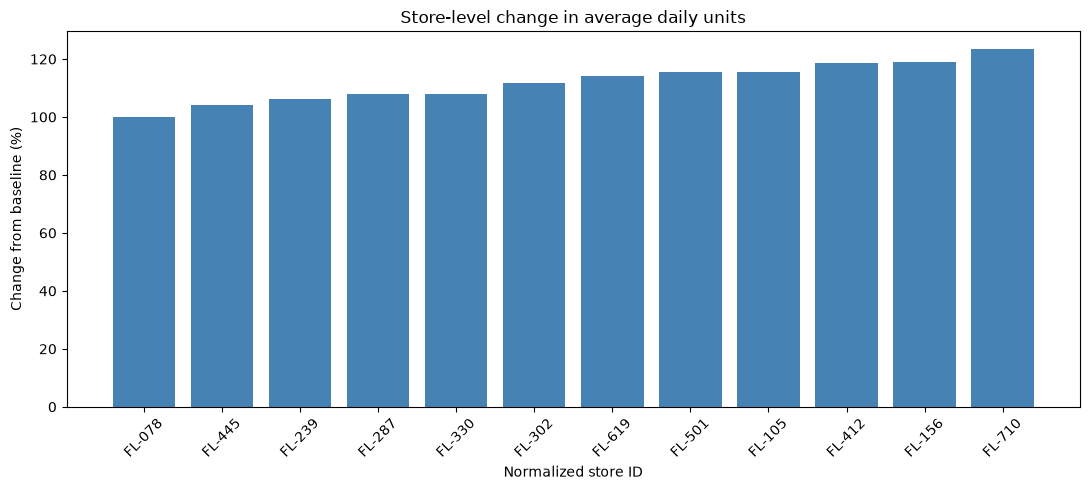

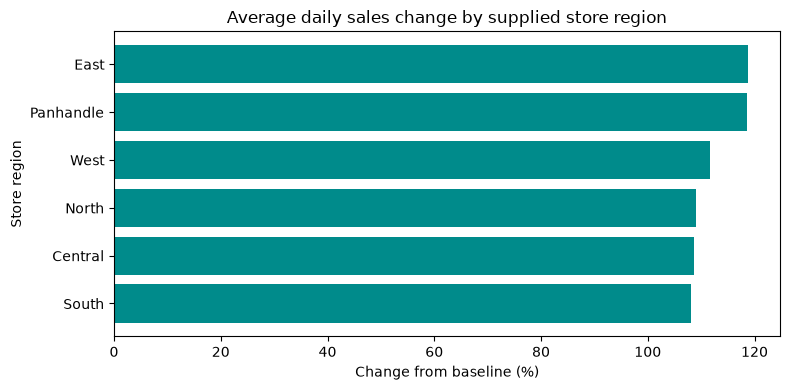

**Finding.** The IQR rule flags no store-level percentage changes as outliers. The first-above-baseline dates range from 2024-09-19 to 2024-09-19, and store-level increases range from 99.9% to 123.4%. Store-level changes vary across the supplied regions, but the files contain no predicted storm path. Regional differences therefore cannot be interpreted as distance-to-track effects.

In [ ]:
store_daily = date_transactions.groupby(["store_id", "date"], as_index=False)["quantity"].sum()
store_baseline = store_daily[store_daily["date"].isin(BASELINE_DATES)].groupby("store_id")["quantity"].sum()
store_surge = store_daily[store_daily["date"].isin(SURGE_DATES)].groupby("store_id")["quantity"].sum()
q4 = pd.concat([store_baseline.rename("baseline_units"), store_surge.rename("surge_units")], axis=1).fillna(0)
q4["baseline_daily_avg"] = q4["baseline_units"] / len(BASELINE_DATES)
q4["surge_daily_avg"] = q4["surge_units"] / len(SURGE_DATES)
q4["increase_pct"] = ((q4["surge_daily_avg"] / q4["baseline_daily_avg"]) - 1) * 100
q4.loc[q4["baseline_daily_avg"].eq(0), "increase_pct"] = float("nan")
q4["first_above_baseline_date"] = pd.NaT
for store_id in q4.index:
    baseline_avg = q4.loc[store_id, "baseline_daily_avg"]
    candidates = store_daily[(store_daily["store_id"] == store_id) & store_daily["date"].isin(SURGE_DATES) & (store_daily["quantity"] > baseline_avg)]
    if not candidates.empty:
        q4.loc[store_id, "first_above_baseline_date"] = candidates["date"].min()

q4 = q4.reset_index().merge(stores[["store_id", "city", "region"]], on="store_id", how="left")
valid_pct = q4["increase_pct"].dropna()
if len(valid_pct) >= 4:
    lower, upper = valid_pct.quantile(0.25), valid_pct.quantile(0.75)
    spread = upper - lower
    q4["outlier"] = (q4["increase_pct"] < lower - 1.5 * spread) | (q4["increase_pct"] > upper + 1.5 * spread)
else:
    q4["outlier"] = False
display(q4[["store_id", "city", "region", "baseline_daily_avg", "surge_daily_avg", "increase_pct", "first_above_baseline_date", "outlier"]].sort_values("increase_pct", ascending=False).round(1))

region_totals = q4.groupby("region", dropna=False)[["baseline_units", "surge_units"]].sum()
region_totals["increase_pct"] = ((region_totals["surge_units"] / region_totals["baseline_units"]) - 1) * 100
display(region_totals.sort_values("increase_pct", ascending=False).round(1))

fig, ax = plt.subplots(figsize=(11, 5))
colors = ["tomato" if value else "steelblue" for value in q4.sort_values("increase_pct")["outlier"]]
ordered = q4.sort_values("increase_pct")
ax.bar(ordered["store_id"], ordered["increase_pct"], color=colors)
ax.set(title="Store-level change in average daily units", xlabel="Normalized store ID", ylabel="Change from baseline (%)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
region_plot = region_totals.sort_values("increase_pct")
ax.barh(region_plot.index.astype(str), region_plot["increase_pct"], color="darkcyan")
ax.set(title="Average daily sales change by supplied store region", xlabel="Change from baseline (%)", ylabel="Store region")
plt.tight_layout()
plt.show()

if q4["outlier"].any():
    outlier_stores = ", ".join(q4.loc[q4["outlier"], "store_id"].astype(str))
    outlier_text = f"The IQR rule flags {outlier_stores} for review."
else:
    outlier_text = "The IQR rule flags no store-level percentage changes as outliers."
display(Markdown(
    f"**Finding.** {outlier_text} The first-above-baseline dates range from {q4['first_above_baseline_date'].min().date()} to {q4['first_above_baseline_date'].max().date()}, "
    f"and store-level increases range from {q4['increase_pct'].min():.1f}% to {q4['increase_pct'].max():.1f}%. Store-level changes vary across the supplied regions, but the files contain no predicted storm path. "
    "Regional differences therefore cannot be interpreted as distance-to-track effects."
))


## Question 5: Signal versus artifact — board games

The catalog and POS records identify individual Monopoly/board-game SKUs. The SQLite daily sales table aggregates all entertainment items, while inventory is SKU-level. Compare the board-game POS trend with broad Entertainment sales and board-game on-hand/on-order inventory. Because the database summary is not SKU-specific and inventory snapshot timing is not documented, neither should be treated as direct proof of board-game sales or stockout causality.

Board-game SKUs identified from the product catalog:


,sku,product_name_clean,catalog_category
14,BG-MONO,Monopoly Board Game,Entertainment
15,MONOPOLY-01,Monopoly Board Game,Entertainment
16,GAME-MONO,Board Game - Monopoly,Entertainment


Board-game units in baseline: 320; in pre-event week: 780; change: 143.8%


,date,db_entertainment_units,pos_entertainment_units,board_game_units,units_on_hand,units_on_order,reorder_point
11,2024-09-12,652.0,96,37,1053,447.0,294
12,2024-09-13,524.0,88,39,935,400.0,323
13,2024-09-14,588.5,96,40,1437,379.0,336
14,2024-09-15,539.5,87,35,1688,433.0,372
15,2024-09-16,850.5,145,68,641,146.0,240
16,2024-09-17,800.0,131,49,1587,490.0,391
17,2024-09-18,735.0,128,52,682,224.0,196
18,2024-09-19,783.0,141,63,1366,261.0,252
19,2024-09-20,760.0,121,43,1500,387.0,384
20,2024-09-21,1370.0,205,113,190,236.0,282


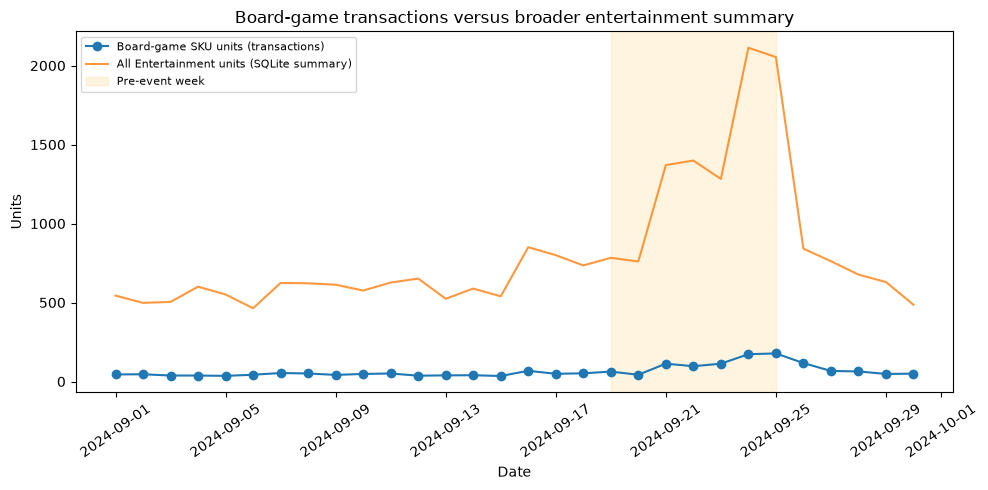

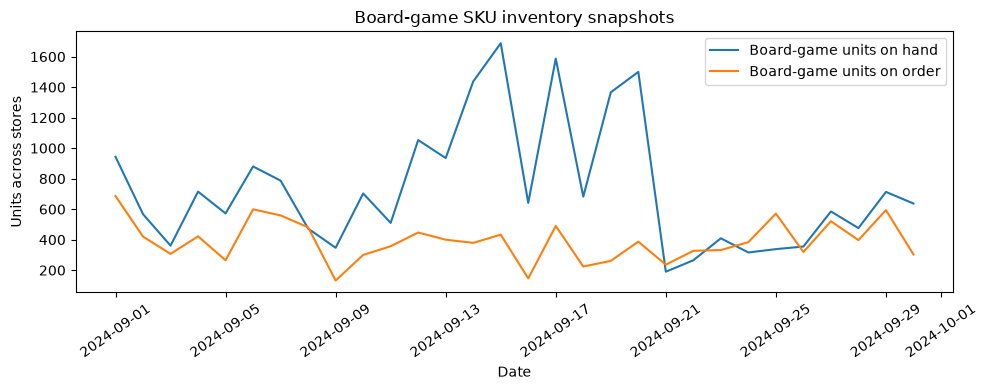

**Evidence-based recommendation.** The cleaned POS records show higher board-game units in the pre-event week. Consider a modest, targeted buffer for the catalog-identified board-game SKUs, then validate it against store-level inventory; do not scale from the broad Entertainment summary alone. The SQLite sales summary combines board games with playing cards and streaming devices, so it cannot independently validate a board-game increase. The SKU-level inventory table adds context but does not document whether snapshots are before or after daily sales.

In [ ]:
board_game_pattern = r"board game|monopoly"
board_game_catalog = products[
    products["product_name_clean"].str.contains(board_game_pattern, case=False, regex=True, na=False)
    & products["catalog_category"].eq("Entertainment")
]
board_game_skus = set(board_game_catalog["sku"].dropna())
print("Board-game SKUs identified from the product catalog:")
display(board_game_catalog[["sku", "product_name_clean", "catalog_category"]])

board_games = date_transactions[date_transactions["sku"].isin(board_game_skus)].copy()
board_game_daily = board_games.groupby("date", as_index=False)["quantity"].sum().rename(columns={"quantity": "board_game_units"})
board_baseline = board_games.loc[board_games["date"].isin(BASELINE_DATES), "quantity"].sum()
board_surge = board_games.loc[board_games["date"].isin(SURGE_DATES), "quantity"].sum()
board_pct = ((board_surge / board_baseline) - 1) * 100 if board_baseline else float("nan")
print(f"Board-game units in baseline: {board_baseline:.0f}; in pre-event week: {board_surge:.0f}; change: {board_pct:.1f}%")

db_sales = db_sales_raw.copy()
def parse_db_date(value):
    text = str(value).strip()
    if re.fullmatch(r"\d{8}", text):
        return pd.to_datetime(text, format="%Y%m%d", errors="coerce")
    return pd.to_datetime(text, format="mixed", errors="coerce")

db_sales["date"] = db_sales["date"].map(parse_db_date).dt.normalize()
db_sales["store_id"] = db_sales["store_id"].map(clean_store_id)
db_sales["category"] = db_sales["category"].map(clean_category)
db_entertainment = db_sales[db_sales["category"].eq("Entertainment")].groupby("date", as_index=False)["total_units"].sum()
db_entertainment = db_entertainment.rename(columns={"total_units": "db_entertainment_units"})

inventory = inventory_raw.copy()
inventory["date"] = pd.to_datetime(inventory["date"], format="mixed", errors="coerce").dt.normalize()
inventory["store_id"] = inventory["store_id"].map(clean_store_id)
inventory["sku"] = inventory["sku"].astype("string").str.strip().str.upper()
for column in ["units_on_hand", "units_on_order", "reorder_point"]:
    inventory[column] = pd.to_numeric(inventory[column], errors="coerce")
board_inventory = inventory[inventory["sku"].isin(board_game_skus)].groupby("date", as_index=False).agg(
    units_on_hand=("units_on_hand", "sum"),
    units_on_order=("units_on_order", "sum"),
    reorder_point=("reorder_point", "sum"),
)

entertainment_pos = date_transactions[date_transactions["category"].eq("Entertainment")].groupby("date", as_index=False)["quantity"].sum().rename(columns={"quantity": "pos_entertainment_units"})
evidence = db_entertainment.merge(entertainment_pos, on="date", how="outer").merge(board_game_daily, on="date", how="outer").merge(board_inventory, on="date", how="left").sort_values("date")
display(evidence[(evidence["date"].isin(BASELINE_DATES.union(SURGE_DATES)))].round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(board_game_daily["date"], board_game_daily["board_game_units"], marker="o", label="Board-game SKU units (transactions)")
ax.plot(db_entertainment["date"], db_entertainment["db_entertainment_units"], alpha=0.8, label="All Entertainment units (SQLite summary)")
ax.axvspan(SURGE_DATES.min(), SURGE_DATES.max(), color="orange", alpha=0.12, label="Pre-event week")
ax.set(title="Board-game transactions versus broader entertainment summary", xlabel="Date", ylabel="Units")
ax.legend(fontsize=8)
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(board_inventory["date"], board_inventory["units_on_hand"], label="Board-game units on hand")
ax.plot(board_inventory["date"], board_inventory["units_on_order"], label="Board-game units on order")
ax.set(title="Board-game SKU inventory snapshots", xlabel="Date", ylabel="Units across stores")
ax.legend()
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

if pd.notna(board_pct) and board_pct > 0 and board_surge > board_baseline:
    recommendation = "The cleaned POS records show higher board-game units in the pre-event week. Consider a modest, targeted buffer for the catalog-identified board-game SKUs, then validate it against store-level inventory; do not scale from the broad Entertainment summary alone."
else:
    recommendation = "The supplied evidence does not establish a board-game-only pre-event surge. Do not make a broad extra-stock commitment from the Entertainment category summary alone; review store-level SKU sales and inventory first."
display(Markdown(
    f"**Evidence-based recommendation.** {recommendation} The SQLite sales summary combines board games with playing cards and streaming devices, so it cannot independently validate a board-game increase. "
    "The SKU-level inventory table adds context but does not document whether snapshots are before or after daily sales."
))


## Data and method notes

- Exact repeated transaction IDs were confirmed in the supplied file and are reduced to one record per ID. Negative and unparseable quantities are excluded from unit totals; missing timestamps are not imputed.
- The product catalog is the lookup for canonical SKUs and product identity. Category spelling/case variants are mapped to ten common category labels.
- Percent change compares equal seven-day periods and is undefined when baseline volume is zero.
- Open-Meteo values are real API data for the supplied coordinates; the request code and API base URL are included above. Correlations and lag checks are exploratory and do not demonstrate causation.
- The store-region comparison is a proxy because no predicted storm-path data was supplied. The supplied Tallahassee record has no coordinates and is omitted from location-specific weather calls.
- The SQLite entertainment sales summary is broader than board games, so the recommendation uses transaction SKU evidence and inventory as separate, limited sources.
